# 05 · Predictive Modelling

Two prediction tasks, chosen from what the EDA (notebook 04) showed matters:

| Task | Question | Unit of prediction |
|---|---|---|
| **A · SoC estimation** | Can battery state of charge be estimated from voltage, current and temperature alone, as a virtual sensor? | one sample per second |
| **B · Segment energy** | How much energy per km will a stretch of driving cost, given speed, temperature and heating? | one driving segment |

**Benchmark: 8 models and a stacked ensemble for each task**

| Family | Models |
|---|---|
| Linear | Ridge, ElasticNet, polynomial Ridge (degree 2) |
| Tree ensembles | Random Forest, Extra Trees, LightGBM, XGBoost |
| Neural network | MLP |
| Ensemble | stacked ensemble of all 8 (non-negative linear blend) |

**Protocol**
1. **Locked test set:** 14 trips (7 summer, 7 winter) are set aside before anything else and scored once, at the end.
2. **Screening:** all 8 models with sensible default settings, scored by 5-fold **GroupKFold** cross-validation on the
   other 56 trips. Grouping by trip means a model is always scored on trips it has never seen.
3. **Tuning:** the **3 best** models from screening are tuned with **Optuna** (TPE sampler, fixed budget per model),
   using the same trip-grouped cross-validation. Tuning only the top 3 keeps the search fair (the ranking can change
   after tuning) without spending hours on models that are clearly behind.
4. **Stacking:** a non-negative linear blend of all 8 models' out-of-fold predictions. Its own score comes from a
   second, trip-grouped cross-validation.
5. **Selection:** the candidate with the lowest cross-validated MAE is the final model. Only then is the test set scored.

No leakage: displayed SoC, min/max SoC and anything that already encodes SoC are excluded from Task A.

In [1]:
from pathlib import Path
import os
import time
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))
warnings.filterwarnings("ignore")

import duckdb
import joblib
import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from xgboost import XGBRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "warehouse" / "volvo.duckdb"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
SEED = 42
N_FOLDS = 5
TOP_K = 3
SEASON_COLORS = {"summer": "#F29C38", "winter": "#2D7FF9"}
FAMILY_COLORS = {"linear": "#14213D", "tree ensemble": "#13A89E", "neural network": "#7A5CFA", "ensemble": "#E4572E"}

pio.renderers.default = "notebook_connected"
pio.templates.default = "plotly_white"
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = duckdb.connect(str(DB_PATH))


def save_figure(fig, name):
    fig.write_html(FIGURES / f"{name}.html", include_plotlyjs="cdn")
    fig.show()

## 0 · Locked test trips and evaluation helpers

In [2]:
trips = con.sql("SELECT trip_id, season FROM clean.trips ORDER BY trip_id").df()
rng = np.random.default_rng(SEED)
test_trips = sorted(t for s in ["summer", "winter"]
                    for t in rng.choice(trips.trip_id[trips.season == s].to_numpy(), 7, replace=False))
train_trips = sorted(set(trips.trip_id) - set(test_trips))
print("test trips :", test_trips)
print(f"train trips: {len(train_trips)}")


def metrics(y, p):
    return dict(mae=mean_absolute_error(y, p), rmse=root_mean_squared_error(y, p), r2=r2_score(y, p))


def oof_predictions(model, X, y, groups):
    pred = np.zeros(len(y))
    for tr, va in GroupKFold(N_FOLDS).split(X, y, groups):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        pred[va] = m.predict(X.iloc[va])
    return pred

test trips : ['TripA03', 'TripA13', 'TripA19', 'TripA21', 'TripA27', 'TripA30', 'TripA32', 'TripB05', 'TripB18', 'TripB24', 'TripB25', 'TripB27', 'TripB32', 'TripB38']
train trips: 56


## 1 · The model zoo

Default settings are deliberately reasonable, not tuned. The search spaces are used only for the 3 models that
reach the tuning stage.

In [3]:
FAMILY = {"Ridge": "linear", "ElasticNet": "linear", "Polynomial Ridge": "linear", "Random Forest": "tree ensemble",
          "Extra Trees": "tree ensemble", "LightGBM": "tree ensemble", "XGBoost": "tree ensemble", "MLP": "neural network"}


def build(name, **p):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=p.get("alpha", 1.0)))
    if name == "ElasticNet":
        return make_pipeline(StandardScaler(), ElasticNet(alpha=p.get("alpha", 0.01), l1_ratio=p.get("l1_ratio", 0.5),
                                                          max_iter=10000))
    if name == "Polynomial Ridge":
        return make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                             Ridge(alpha=p.get("alpha", 10.0)))
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth"),
                                     min_samples_leaf=p.get("min_samples_leaf", 5), max_features=p.get("max_features", 0.5),
                                     n_jobs=-1, random_state=SEED)
    if name == "Extra Trees":
        return ExtraTreesRegressor(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth"),
                                   min_samples_leaf=p.get("min_samples_leaf", 5), max_features=p.get("max_features", 0.7),
                                   n_jobs=-1, random_state=SEED)
    if name == "LightGBM":
        return lgb.LGBMRegressor(n_estimators=p.get("n_estimators", 500), learning_rate=p.get("learning_rate", 0.05),
                                 num_leaves=p.get("num_leaves", 31), min_child_samples=p.get("min_child_samples", 50),
                                 subsample=p.get("subsample", 0.8), subsample_freq=1,
                                 colsample_bytree=p.get("colsample_bytree", 0.9), reg_lambda=p.get("reg_lambda", 0.0),
                                 random_state=SEED, verbose=-1, n_jobs=-1)
    if name == "XGBoost":
        return XGBRegressor(n_estimators=p.get("n_estimators", 500), learning_rate=p.get("learning_rate", 0.05),
                            max_depth=p.get("max_depth", 6), min_child_weight=p.get("min_child_weight", 5),
                            subsample=p.get("subsample", 0.8), colsample_bytree=p.get("colsample_bytree", 0.9),
                            reg_lambda=p.get("reg_lambda", 1.0), tree_method="hist", random_state=SEED, n_jobs=-1)
    if name == "MLP":
        return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=p.get("hidden", (64, 32)),
                                                            alpha=p.get("alpha", 1e-3),
                                                            learning_rate_init=p.get("learning_rate_init", 1e-3),
                                                            early_stopping=True, max_iter=500, random_state=SEED))
    raise KeyError(name)


def search_space(name, t):
    if name in ("Ridge", "Polynomial Ridge"):
        return {"alpha": t.suggest_float("alpha", 1e-3, 1e3, log=True)}
    if name == "ElasticNet":
        return {"alpha": t.suggest_float("alpha", 1e-4, 10, log=True), "l1_ratio": t.suggest_float("l1_ratio", 0.0, 1.0)}
    if name in ("Random Forest", "Extra Trees"):
        return {"n_estimators": t.suggest_int("n_estimators", 100, 400, step=50),
                "max_depth": t.suggest_categorical("max_depth", [None, 8, 12, 16, 24]),
                "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 50, log=True),
                "max_features": t.suggest_float("max_features", 0.3, 1.0)}
    if name == "LightGBM":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 1500, step=100),
                "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "num_leaves": t.suggest_int("num_leaves", 8, 128, log=True),
                "min_child_samples": t.suggest_int("min_child_samples", 10, 200, log=True),
                "subsample": t.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    if name == "XGBoost":
        return {"n_estimators": t.suggest_int("n_estimators", 200, 1500, step=100),
                "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                "max_depth": t.suggest_int("max_depth", 3, 10),
                "min_child_weight": t.suggest_float("min_child_weight", 1, 30, log=True),
                "subsample": t.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
                "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    if name == "MLP":
        hidden = t.suggest_categorical("hidden", ["32", "64", "64-32", "128-64"])
        return {"hidden": tuple(int(h) for h in hidden.split("-")),
                "alpha": t.suggest_float("alpha", 1e-5, 1e-1, log=True),
                "learning_rate_init": t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True)}
    raise KeyError(name)


print(f"{len(FAMILY)} models:", ", ".join(FAMILY))

8 models: Ridge, ElasticNet, Polynomial Ridge, Random Forest, Extra Trees, LightGBM, XGBoost, MLP


## 2 · One benchmark routine for both tasks

`run_benchmark` does screening, tuning of the top 3, stacking and selection, and returns everything needed to score
the test set. For the large SoC dataset, Optuna trials use every 3rd training sample (still grouped by trip) to keep
the search fast; the final models are refit on all training samples.

In [4]:
def run_benchmark(task, train, features, target, n_trials, timeout_s, tune_every=1):
    X, y, g = train[features], train[target], train.trip_id
    rows, oof, final = [], {}, {}

    # 1) screening with default settings
    for name in FAMILY:
        t0 = time.time()
        oof[name] = oof_predictions(build(name), X, y, g)
        rows.append(dict(task=task, model=name, family=FAMILY[name], stage="default",
                         **metrics(y, oof[name]), seconds=round(time.time() - t0, 1)))
        final[name] = build(name)
    screen = pd.DataFrame(rows).sort_values("mae")
    top = screen.model.head(TOP_K).tolist()
    print(f"[{task}] screening done, top {TOP_K}: {top}")

    # 2) Optuna on the top 3, on a thinned sample for speed, scored with the same grouped CV
    sub = train.iloc[::tune_every]
    tuning = []
    for name in top:
        def objective(trial):
            model = build(name, **search_space(name, trial))
            return mean_absolute_error(sub[target], oof_predictions(model, sub[features], sub[target], sub.trip_id))
        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(objective, n_trials=n_trials, timeout=timeout_s)
        best = search_space(name, optuna.trial.FixedTrial(study.best_params))
        tuned = build(name, **best)
        t0 = time.time()
        pred = oof_predictions(tuned, X, y, g)
        m = metrics(y, pred)
        rows.append(dict(task=task, model=name, family=FAMILY[name], stage="tuned", **m, seconds=round(time.time() - t0, 1)))
        tuning.append(dict(task=task, model=name, trials=len(study.trials), best_params=str(study.best_params),
                           default_mae=float(screen.set_index("model").mae[name]), tuned_mae=m["mae"]))
        if m["mae"] < screen.set_index("model").mae[name]:  # keep tuning only if it really helped on the full data
            oof[name], final[name] = pred, tuned
        print(f"[{task}] tuned {name}: {len(study.trials)} trials, CV MAE {screen.set_index('model').mae[name]:.3f} -> {m['mae']:.3f}")

    # 3) stacking: non-negative blend of the 8 out-of-fold predictions, scored by a second grouped CV
    names = list(FAMILY)
    Z = pd.DataFrame({n: oof[n] for n in names})
    meta = LinearRegression(positive=True)
    stack_oof = oof_predictions(meta, Z, y, g)
    rows.append(dict(task=task, model="Stacked ensemble", family="ensemble", stage="stacked", **metrics(y, stack_oof),
                     seconds=np.nan))
    meta.fit(Z, y)
    weights = pd.Series(meta.coef_, index=names)
    oof["Stacked ensemble"] = stack_oof

    results = pd.DataFrame(rows)
    # best version of each model (tuned if it helped), then the stack
    best_rows = results.sort_values("mae").drop_duplicates("model")
    selected = best_rows.model.iat[0]
    results["is_selected"] = (results.model == selected) & (results.mae == best_rows.mae.iat[0])
    print(f"[{task}] selected by cross-validation: {selected} (CV MAE {best_rows.mae.iat[0]:.3f})")
    return dict(results=results, tuning=pd.DataFrame(tuning), oof=oof, final=final, meta=meta, weights=weights,
                selected=selected, features=features, target=target)


def fit_and_predict(bench, train, test):
    # refit every base model on all training trips, predict the test trips; stack uses the fitted meta-model
    X, y = train[bench["features"]], train[bench["target"]]
    preds = {}
    for name, model in bench["final"].items():
        bench["final"][name] = model.fit(X, y)
        preds[name] = bench["final"][name].predict(test[bench["features"]])
    preds["Stacked ensemble"] = bench["meta"].predict(pd.DataFrame({n: preds[n] for n in FAMILY}))
    return preds


def test_table(task, bench, test, preds):
    rows = [dict(task=task, model=n, family=FAMILY.get(n, "ensemble"), **metrics(test[bench["target"]], p),
                 is_selected=n == bench["selected"]) for n, p in preds.items()]
    return pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)

## 3 · Task A: SoC estimation

**Data:** every sample at 1 Hz (every 10th sample), excluding the flagged SoC gaps from notebook 02.

**Features:** only what a battery sensor reads now or in the last minute:
smoothed voltage and current, the relaxed voltage (the last low-load voltage, close to open-circuit voltage),
battery and ambient temperature, power, and 60-second rolling means of current and voltage.

In [5]:
soc = con.sql("""
    SELECT c.trip_id, c.series, c.time_s, c.soc_pct, c.batt_temp_c, c.ambient_temp_c,
           s.voltage_smooth_v, s.current_smooth_a, s.power_smooth_kw, s.v_relaxed, s.phase
    FROM clean.trip_signals c JOIN signal.samples s USING (trip_id, row_idx)
    WHERE c.row_idx % 10 = 0 AND NOT c.soc_gap AND c.soc_pct IS NOT NULL
    ORDER BY c.trip_id, c.row_idx
""").df()
grp = soc.groupby("trip_id")
soc["current_mean_60s_a"] = grp.current_smooth_a.transform(lambda x: x.rolling(60, min_periods=1).mean())
soc["voltage_mean_60s_v"] = grp.voltage_smooth_v.transform(lambda x: x.rolling(60, min_periods=1).mean())
soc["season"] = soc.series.map({"A": "summer", "B": "winter"})

SOC_FEATURES = ["voltage_smooth_v", "current_smooth_a", "power_smooth_kw", "v_relaxed", "batt_temp_c",
                "ambient_temp_c", "current_mean_60s_a", "voltage_mean_60s_v"]
train_a = soc[soc.trip_id.isin(train_trips)].reset_index(drop=True)
test_a = soc[soc.trip_id.isin(test_trips)].reset_index(drop=True)
print(f"samples: train {len(train_a):,} | test {len(test_a):,}")

samples: train 88,363 | test 18,068


In [6]:
bench_a = run_benchmark("A · SoC estimation", train_a, SOC_FEATURES, "soc_pct", n_trials=25, timeout_s=300, tune_every=3)
bench_a["results"].sort_values("mae").round(3)

[A · SoC estimation] screening done, top 3: ['Polynomial Ridge', 'Ridge', 'ElasticNet']


[A · SoC estimation] tuned Polynomial Ridge: 25 trials, CV MAE 2.530 -> 2.457


[A · SoC estimation] tuned Ridge: 25 trials, CV MAE 2.734 -> 2.734


[A · SoC estimation] tuned ElasticNet: 25 trials, CV MAE 2.743 -> 2.734


[A · SoC estimation] selected by cross-validation: Stacked ensemble (CV MAE 2.408)


,task,model,family,stage,mae,rmse,r2,seconds,is_selected
11,A · SoC estimation,Stacked ensemble,ensemble,stacked,2.408,3.304,0.952,NaN,True
8,A · SoC estimation,Polynomial Ridge,linear,tuned,2.457,3.321,0.951,0.6,False
2,A · SoC estimation,Polynomial Ridge,linear,default,2.530,3.524,0.945,0.9,False
9,A · SoC estimation,Ridge,linear,tuned,2.734,3.621,0.942,0.1,False
0,A · SoC estimation,Ridge,linear,default,2.734,3.621,0.942,0.6,False
10,A · SoC estimation,ElasticNet,linear,tuned,2.734,3.621,0.942,11.2,False
1,A · SoC estimation,ElasticNet,linear,default,2.743,3.626,0.942,16.5,False
5,A · SoC estimation,LightGBM,tree ensemble,default,3.115,4.486,0.911,5.1,False
6,A · SoC estimation,XGBoost,tree ensemble,default,3.171,4.708,0.902,9.3,False
4,A · SoC estimation,Extra Trees,tree ensemble,default,3.260,4.406,0.915,19.8,False


## 4 · Task B: energy per km of a driving segment

**Data:** driving segments from notebook 03 that last at least 60 s and cover at least 0.2 km.
**Target:** net battery energy per 100 km for the segment (energy drawn minus energy recovered).
**Features:** how the segment was driven (mean and spread of speed, mean |acceleration|, climb per km), the conditions
(ambient and battery temperature) and the climate load (heating and A/C power).

In [7]:
seg = con.sql("""
    SELECT g.trip_id, g.segment_no, g.duration_s, -g.energy_kwh AS net_energy_kwh, t.season,
           sum(c.speed_kmh) / 36000                         AS distance_km,
           avg(c.speed_kmh)                                 AS mean_speed_kmh,
           stddev_pop(c.speed_kmh)                          AS speed_std_kmh,
           avg(abs(c.accel_long_ms2))                       AS mean_abs_accel_ms2,
           arg_max(c.elevation_m, c.time_s) - arg_min(c.elevation_m, c.time_s) AS climb_m,
           avg(c.ambient_temp_c)                            AS ambient_temp_c,
           avg(c.batt_temp_c)                               AS batt_temp_c,
           coalesce(avg(c.heating_power_can_kw), 0)         AS heating_kw,
           coalesce(avg(c.aircon_power_kw), 0)              AS aircon_kw
    FROM signal.segments g
    JOIN signal.samples s ON s.trip_id = g.trip_id AND s.segment_no = g.segment_no
    JOIN clean.trip_signals c ON c.trip_id = s.trip_id AND c.row_idx = s.row_idx
    JOIN clean.trips t ON t.trip_id = g.trip_id
    WHERE g.phase = 'driving' AND g.duration_s >= 60
    GROUP BY ALL
""").df()
seg = seg[seg.distance_km >= 0.2].reset_index(drop=True)
seg["climb_m_per_km"] = seg.climb_m / seg.distance_km
seg["kwh_per_100km"] = 100 * seg.net_energy_kwh / seg.distance_km
SEG_FEATURES = ["mean_speed_kmh", "speed_std_kmh", "mean_abs_accel_ms2", "climb_m_per_km", "ambient_temp_c",
                "batt_temp_c", "heating_kw", "aircon_kw"]
train_b = seg[seg.trip_id.isin(train_trips)].reset_index(drop=True)
test_b = seg[seg.trip_id.isin(test_trips)].reset_index(drop=True)
print(f"driving segments: {len(seg)} (train {len(train_b)}, test {len(test_b)})")

driving segments: 294 (train 238, test 56)


In [8]:
bench_b = run_benchmark("B · segment energy", train_b, SEG_FEATURES, "kwh_per_100km", n_trials=40, timeout_s=180)
bench_b["results"].sort_values("mae").round(3)

[B · segment energy] screening done, top 3: ['MLP', 'ElasticNet', 'Ridge']


[B · segment energy] tuned MLP: 40 trials, CV MAE 3.035 -> 3.023


[B · segment energy] tuned ElasticNet: 40 trials, CV MAE 3.254 -> 3.245


[B · segment energy] tuned Ridge: 40 trials, CV MAE 3.255 -> 3.253
[B · segment energy] selected by cross-validation: Stacked ensemble (CV MAE 2.872)


,task,model,family,stage,mae,rmse,r2,seconds,is_selected
11,B · segment energy,Stacked ensemble,ensemble,stacked,2.872,5.243,0.790,NaN,True
8,B · segment energy,MLP,neural network,tuned,3.023,4.892,0.817,1.0,False
7,B · segment energy,MLP,neural network,default,3.035,4.921,0.815,1.1,False
9,B · segment energy,ElasticNet,linear,tuned,3.245,5.678,0.754,0.0,False
10,B · segment energy,Ridge,linear,tuned,3.253,5.654,0.756,0.0,False
1,B · segment energy,ElasticNet,linear,default,3.254,5.673,0.754,0.0,False
0,B · segment energy,Ridge,linear,default,3.255,5.674,0.754,0.0,False
4,B · segment energy,Extra Trees,tree ensemble,default,3.450,9.501,0.310,1.0,False
3,B · segment energy,Random Forest,tree ensemble,default,3.485,9.654,0.288,1.5,False
2,B · segment energy,Polynomial Ridge,linear,default,3.486,9.314,0.337,0.0,False


## 5 · Results

### 5.1 Benchmark: cross-validated error of every model, default vs tuned

Lower is better. Darker bars are the tuned versions of the top 3 models.

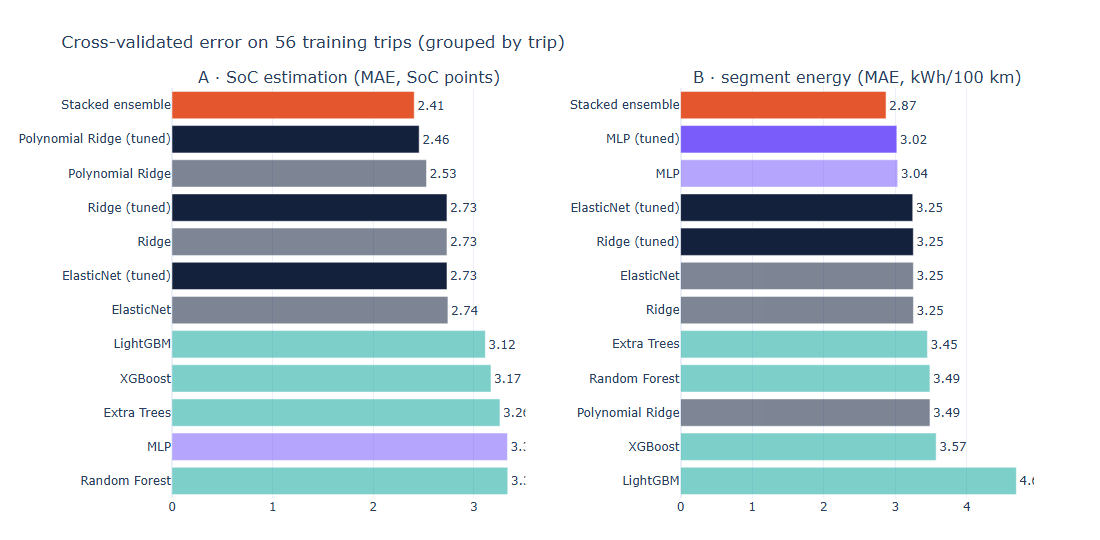

In [9]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["A · SoC estimation (MAE, SoC points)",
                                                    "B · segment energy (MAE, kWh/100 km)"], horizontal_spacing=0.18)
for col, bench in enumerate([bench_a, bench_b], start=1):
    r = bench["results"].copy()
    r["label"] = r.model + np.where(r.stage == "tuned", " (tuned)", "")
    r = r.sort_values("mae", ascending=False)
    fig.add_trace(go.Bar(x=r.mae, y=r.label, orientation="h", text=r.mae.round(2), textposition="outside",
                         marker_color=[FAMILY_COLORS[f] for f in r.family],
                         marker_opacity=[1.0 if s != "default" else 0.55 for s in r.stage],
                         hovertemplate="%{y}<br>MAE %{x:.3f}<extra></extra>", showlegend=False), row=1, col=col)
fig.update_layout(height=520, title="Cross-validated error on 56 training trips (grouped by trip)",
                  margin=dict(l=10, r=40, t=80, b=30))
save_figure(fig, "05_benchmark")

In [10]:
tuning = pd.concat([bench_a["tuning"], bench_b["tuning"]], ignore_index=True)
tuning["improvement_pct"] = 100 * (1 - tuning.tuned_mae / tuning.default_mae)
tuning.round(3)

,task,model,trials,best_params,default_mae,tuned_mae,improvement_pct
0,A · SoC estimation,Polynomial Ridge,25,{'alpha': 157.41890047456639},2.530,2.457,2.870
1,A · SoC estimation,Ridge,25,{'alpha': 0.001025874037478159},2.734,2.734,0.001
2,A · SoC estimation,ElasticNet,25,"{'alpha': 0.00010907785690006149, 'l1_ratio': ...",2.743,2.734,0.339
3,B · segment energy,MLP,40,"{'hidden': '64-32', 'alpha': 0.000105184374608...",3.035,3.023,0.412
4,B · segment energy,ElasticNet,40,"{'alpha': 0.06788203230621184, 'l1_ratio': 0.9...",3.254,3.245,0.278
5,B · segment energy,Ridge,40,{'alpha': 0.001025874037478159},3.255,3.253,0.052


In [11]:
weights = pd.concat([bench_a["weights"].rename("A · SoC estimation"), bench_b["weights"].rename("B · segment energy")], axis=1)
print("stacked-ensemble weights (non-negative blend of the 8 models):")
weights.round(3)

stacked-ensemble weights (non-negative blend of the 8 models):


,A · SoC estimation,B · segment energy
Ridge,0.168,0.180
ElasticNet,0.000,0.000
Polynomial Ridge,0.529,0.324
Random Forest,0.029,0.000
Extra Trees,0.000,0.000
LightGBM,0.141,0.000
XGBoost,0.000,0.147
MLP,0.134,0.292


### 5.2 Test set: scored once, after selection

In [12]:
preds_a = fit_and_predict(bench_a, train_a, test_a)
preds_b = fit_and_predict(bench_b, train_b, test_b)
test_a_tbl = test_table("A · SoC estimation", bench_a, test_a, preds_a)
test_b_tbl = test_table("B · segment energy", bench_b, test_b, preds_b)
test_a["soc_pred"] = preds_a[bench_a["selected"]]
test_a["abs_error"] = (test_a.soc_pred - test_a.soc_pct).abs()
test_b["pred_kwh_per_100km"] = preds_b[bench_b["selected"]]
test_b["abs_error"] = (test_b.pred_kwh_per_100km - test_b.kwh_per_100km).abs()
joblib.dump({"models": bench_a["final"], "meta": bench_a["meta"], "selected": bench_a["selected"],
             "features": SOC_FEATURES}, MODELS / "soc_model.joblib")
joblib.dump({"models": bench_b["final"], "meta": bench_b["meta"], "selected": bench_b["selected"],
             "features": SEG_FEATURES}, MODELS / "segment_energy_model.joblib")
print("selected:", bench_a["selected"], "|", bench_b["selected"])
print("(every model is scored below for transparency; the selection was fixed by cross-validation beforehand)")
pd.concat([test_a_tbl, test_b_tbl]).round(3)

selected: Stacked ensemble | Stacked ensemble
(every model is scored below for transparency; the selection was fixed by cross-validation beforehand)


,task,model,family,mae,rmse,r2,is_selected
0,A · SoC estimation,MLP,neural network,2.103,3.032,0.961,False
1,A · SoC estimation,Stacked ensemble,ensemble,2.124,2.976,0.962,True
2,A · SoC estimation,Random Forest,tree ensemble,2.329,3.465,0.949,False
3,A · SoC estimation,LightGBM,tree ensemble,2.329,3.436,0.950,False
4,A · SoC estimation,Extra Trees,tree ensemble,2.379,3.567,0.946,False
5,A · SoC estimation,Polynomial Ridge,linear,2.422,3.282,0.954,False
6,A · SoC estimation,XGBoost,tree ensemble,2.460,3.611,0.944,False
7,A · SoC estimation,Ridge,linear,2.889,3.556,0.946,False
8,A · SoC estimation,ElasticNet,linear,2.889,3.556,0.946,False
0,B · segment energy,Random Forest,tree ensemble,1.987,2.930,0.740,False


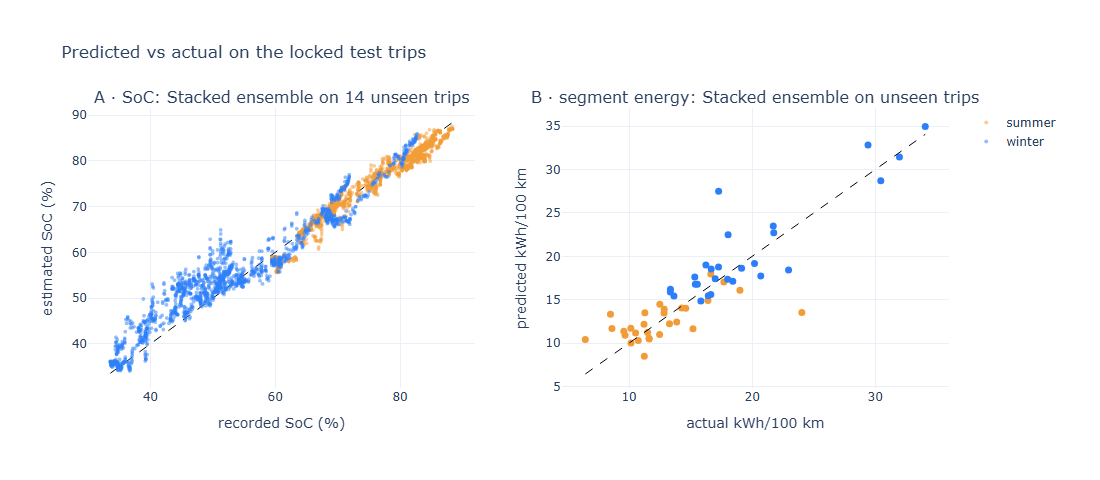

In [13]:
fig = make_subplots(rows=1, cols=2, subplot_titles=[f"A · SoC: {bench_a['selected']} on 14 unseen trips",
                                                    f"B · segment energy: {bench_b['selected']} on unseen trips"])
sample = test_a.sample(4000, random_state=SEED)
for s, c in SEASON_COLORS.items():
    d = sample[sample.season == s]
    fig.add_trace(go.Scattergl(x=d.soc_pct, y=d.soc_pred, mode="markers", name=s, marker=dict(size=4, color=c, opacity=0.5)),
                  row=1, col=1)
    d = test_b[test_b.season == s]
    fig.add_trace(go.Scatter(x=d.kwh_per_100km, y=d.pred_kwh_per_100km, mode="markers", name=s, showlegend=False,
                             marker=dict(size=7, color=c), text=d.trip_id,
                             hovertemplate="%{text}<br>actual %{x:.1f}<br>predicted %{y:.1f}<extra></extra>"), row=1, col=2)
for col, (lo, hi) in enumerate([(sample.soc_pct.min(), sample.soc_pct.max()),
                                 (test_b.kwh_per_100km.min(), test_b.kwh_per_100km.max())], start=1):
    fig.add_trace(go.Scatter(x=[lo, hi], y=[lo, hi], mode="lines", line=dict(color="black", dash="dash", width=1),
                             showlegend=False), row=1, col=col)
fig.update_xaxes(title_text="recorded SoC (%)", row=1, col=1)
fig.update_yaxes(title_text="estimated SoC (%)", row=1, col=1)
fig.update_xaxes(title_text="actual kWh/100 km", row=1, col=2)
fig.update_yaxes(title_text="predicted kWh/100 km", row=1, col=2)
fig.update_layout(height=460, title="Predicted vs actual on the locked test trips")
save_figure(fig, "05_predicted_vs_actual")

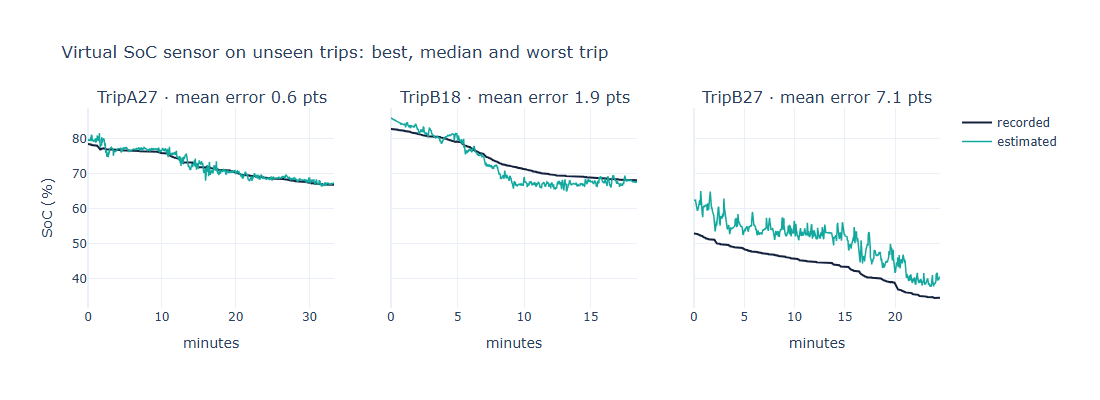

In [14]:
per_trip = test_a.groupby(["trip_id", "season"]).abs_error.mean().sort_values()
show = [per_trip.index[0][0], per_trip.index[len(per_trip) // 2][0], per_trip.index[-1][0]]
fig = make_subplots(rows=1, cols=3, shared_yaxes=True,
                    subplot_titles=[f"{t} · mean error {per_trip.xs(t, level=0).iat[0]:.1f} pts" for t in show])
for col, t in enumerate(show, start=1):
    d = test_a[test_a.trip_id == t]
    fig.add_trace(go.Scatter(x=d.time_s / 60, y=d.soc_pct, name="recorded", line=dict(color="#14213D", width=2),
                             showlegend=col == 1), row=1, col=col)
    fig.add_trace(go.Scatter(x=d.time_s / 60, y=d.soc_pred, name="estimated", line=dict(color="#13A89E", width=1.5),
                             showlegend=col == 1), row=1, col=col)
    fig.update_xaxes(title_text="minutes", row=1, col=col)
fig.update_yaxes(title_text="SoC (%)", row=1, col=1)
fig.update_layout(height=380, title="Virtual SoC sensor on unseen trips: best, median and worst trip")
save_figure(fig, "05_soc_test_trips")

### 5.3 Where the models fail

In [15]:
test_a["batt_temp_band"] = pd.cut(test_a.batt_temp_c, [-5, 5, 10, 15, 20, 35])
test_a["soc_band"] = pd.cut(test_a.soc_pct, [0, 30, 50, 70, 90])
breakdown_a = pd.concat([
    test_a.groupby(col, observed=True).agg(samples=("abs_error", "size"), mae=("abs_error", "mean"),
                                           p90_error=("abs_error", lambda e: e.quantile(.9)))
    .assign(dimension=col).reset_index().rename(columns={col: "level"})
    for col in ["season", "batt_temp_band", "soc_band", "phase"]])
breakdown_a["level"] = breakdown_a.level.astype(str)
test_b["length_band"] = pd.cut(test_b.distance_km, [0.2, 0.5, 1, 2, 100], labels=["0.2-0.5 km", "0.5-1 km", "1-2 km", "> 2 km"])
breakdown_b = pd.concat([
    test_b.groupby(col, observed=True).agg(segments=("abs_error", "size"), mae=("abs_error", "mean"))
    .assign(dimension=col).reset_index().rename(columns={col: "level"})
    for col in ["season", "length_band"]])
breakdown_b["level"] = breakdown_b.level.astype(str)
display(breakdown_a[["dimension", "level", "samples", "mae", "p90_error"]].round(2))
breakdown_b[["dimension", "level", "segments", "mae"]].round(2)

,dimension,level,samples,mae,p90_error
0,season,summer,10030,1.28,2.82
1,season,winter,8038,3.17,7.14
0,batt_temp_band,"(-5, 5]",4201,3.93,8.36
1,batt_temp_band,"(5, 10]",1977,2.71,4.56
2,batt_temp_band,"(10, 15]",1860,1.97,3.64
3,batt_temp_band,"(15, 20]",3475,1.01,1.93
4,batt_temp_band,"(20, 35]",6555,1.43,3.00
0,soc_band,"(30, 50]",3637,4.10,8.19
1,soc_band,"(50, 70]",6607,1.79,3.96
2,soc_band,"(70, 90]",7824,1.49,3.04


,dimension,level,segments,mae
0,season,summer,29,1.90
1,season,winter,27,2.10
0,length_band,0.2-0.5 km,4,1.56
1,length_band,0.5-1 km,12,3.15
2,length_band,1-2 km,18,2.12
3,length_band,> 2 km,22,1.34


### 5.4 What the selected models rely on

Permutation importance on the test trips: how much the test MAE rises when one input is shuffled. It works the same
way for every model type, including the stacked ensemble.

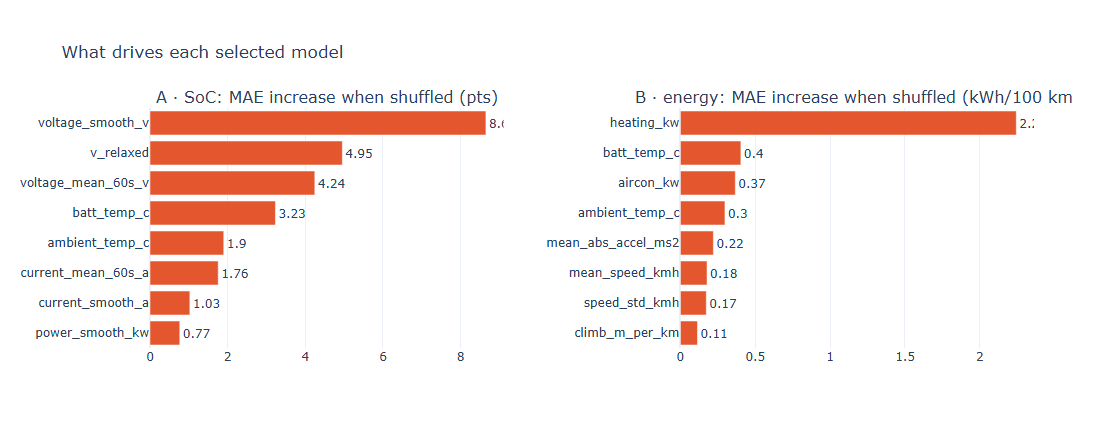

In [16]:
class SelectedModel:
    # wraps the selected model (or the stack) so permutation importance sees one predict()
    def __init__(self, bench):
        self.bench = bench

    def fit(self, X, y):
        return self

    def predict(self, X):
        if self.bench["selected"] != "Stacked ensemble":
            return self.bench["final"][self.bench["selected"]].predict(X)
        Z = pd.DataFrame({n: m.predict(X) for n, m in self.bench["final"].items()})
        return self.bench["meta"].predict(Z[list(FAMILY)])


def importance(bench, test, n):
    sample = test.sample(min(n, len(test)), random_state=SEED)
    pi = permutation_importance(SelectedModel(bench), sample[bench["features"]], sample[bench["target"]],
                                n_repeats=5, random_state=SEED, scoring="neg_mean_absolute_error")
    return pd.Series(pi.importances_mean, index=bench["features"]).clip(lower=0).sort_values(ascending=False)


imp_a, imp_b = importance(bench_a, test_a, 3000), importance(bench_b, test_b, len(test_b))
fig = make_subplots(rows=1, cols=2, subplot_titles=["A · SoC: MAE increase when shuffled (pts)",
                                                    "B · energy: MAE increase when shuffled (kWh/100 km)"],
                    horizontal_spacing=0.2)
for col, imp in enumerate([imp_a, imp_b], start=1):
    s = imp.sort_values()
    fig.add_trace(go.Bar(x=s.values, y=s.index, orientation="h", marker_color="#E4572E", showlegend=False,
                         text=s.round(2), textposition="outside"), row=1, col=col)
fig.update_layout(height=420, title="What drives each selected model", margin=dict(r=40))
save_figure(fig, "05_feature_importance")

## 5.5 · Save results

In [17]:
cv = pd.concat([bench_a["results"], bench_b["results"]], ignore_index=True).assign(split="cross-validation")
cv["model"] = cv.model + np.where(cv.stage == "tuned", " (tuned)", "")
test_rows = pd.concat([test_a_tbl, test_b_tbl], ignore_index=True).assign(split="test", stage="final")
metrics_all = pd.concat([cv, test_rows], ignore_index=True)[["task", "split", "stage", "model", "family", "mae", "rmse", "r2",
                                                             "is_selected"]]
importance_all = pd.concat([
    imp_a.rename("importance").rename_axis("feature").reset_index().assign(task="A · SoC estimation"),
    imp_b.rename("importance").rename_axis("feature").reset_index().assign(task="B · segment energy")])
soc_predictions = test_a[["trip_id", "season", "time_s", "soc_pct", "soc_pred", "abs_error", "batt_temp_c", "phase"]]
train_b["pred_kwh_per_100km"] = bench_b["oof"][bench_b["selected"]]
segment_predictions = pd.concat([train_b.assign(split="train (out-of-fold)"), test_b.assign(split="test")])[
    ["trip_id", "segment_no", "season", "split", "distance_km", "mean_speed_kmh", "ambient_temp_c", "batt_temp_c",
     "heating_kw", "kwh_per_100km", "pred_kwh_per_100km"]]
stack_weights = weights.rename_axis("model").reset_index().melt(id_vars="model", var_name="task", value_name="weight")

con.execute("DROP SCHEMA IF EXISTS model CASCADE")
con.execute("CREATE SCHEMA model")
for table, frame in {"model.metrics": metrics_all, "model.tuning": tuning, "model.stack_weights": stack_weights,
                     "model.feature_importance": importance_all, "model.soc_test_predictions": soc_predictions,
                     "model.segment_predictions": segment_predictions, "model.soc_error_breakdown": breakdown_a,
                     "model.segment_error_breakdown": breakdown_b,
                     "model.test_trips": pd.DataFrame({"trip_id": test_trips})}.items():
    con.register("frame_view", frame)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM frame_view")
    con.unregister("frame_view")
metrics_all.to_csv(REPORTS / "05_model_metrics.csv", index=False)
tuning.to_csv(REPORTS / "05_tuning.csv", index=False)
importance_all.to_csv(REPORTS / "05_feature_importance.csv", index=False)
con.close()
print(f"saved {len(metrics_all)} metric rows")

saved 42 metric rows


## 6 · Findings

**Selected model for both tasks: the stacked ensemble.** It had the lowest cross-validated error in both tasks, and
the gain holds on the 14 locked test trips.

| Task | Stacked ensemble on unseen test trips | Best single model in cross-validation |
|---|---|---|
| A · SoC estimation | **MAE 2.12 SoC points, R² 0.96** | Polynomial Ridge (tuned), CV MAE 2.46 |
| B · segment energy | **MAE 1.99 kWh/100 km, R² 0.76** | MLP (tuned), CV MAE 3.02 |

**1. Blending different model families beats any single model.**
- For SoC, the stack weights polynomial Ridge most (0.53), then Ridge, LightGBM and the MLP.
- For segment energy it blends polynomial Ridge, MLP, Ridge and XGBoost.
- The linear models capture the near-linear battery physics. The tree and neural models add the non-linear parts the linear models miss.

**2. Linear models lead the single-model ranking for SoC.** Terminal voltage is close to open-circuit voltage(SoC)
minus current × resistance. Polynomial Ridge adds the curvature of the voltage–SoC relationship, and tree models
cannot extrapolate to voltage and temperature combinations from unseen trips.

**3. Hyperparameter tuning helped only a little (0–3 %).**
- Optuna (TPE) tuned the top 3 models of each task.
- The best gain was polynomial Ridge for SoC, from 2.53 to 2.46.
- This is an honest result: with sensible defaults, the limit is the information in the signals, not the settings.
- Because the top 3 for SoC were all linear, the tree models were not tuned. They still contribute through the stack.

**4. Cross-validation and test scores differ for Task B,** because a few extreme training segments sit in the
cross-validation folds (the 23 kW heating event in TripB02, a downhill segment that recovered energy). They inflate
the cross-validated RMSE of every model. The ranking was decided on cross-validation before the test set was opened.

**5. Where the models still fail:** a cold battery and low SoC for Task A, and short or winter segments for Task B.
This is the same pattern as before, and it matches the temperature-dependent resistance found in notebook 04.

**What drives the predictions** (permutation importance on the test trips): voltage features dominate SoC estimation,
and heating power dominates energy per km.

**Limitations**
- 70 trips from one car, so the test set has only 14 trips.
- Recorded SoC is itself a BMS estimate, not a lab ground truth.
- The stack's own cross-validated score reuses the same folds as its base models, so it is slightly optimistic.
  The untouched test set confirms it.